# Tópicos em Ciência de Dados

_Especialização em Inteligência Artiﬁcial_

_Professor: Petrus Abreu_

## Módulo 2 — Probabilidade e Variáveis Aleatórias

### Lista de Exercícios

**Aluna: Angelina de Meiras Ottoni**

In [19]:
%pip install pandas matplotlib seaborn scipy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 309.5 kB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.2/35.2 MB 4.2 MB/s eta 0:00:00:00:0100:01
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

In [2]:
url = 'https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv'

In [3]:
df = pd.read_csv(url)

In [4]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
df.shape

(1338, 7)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


## Questão 2 – Análise de Resultados: Teorema de Bayes

### Código 1 – Aplicação do Teorema de Bayes ao dataset de seguros.

In [11]:
high_cost_filter = df['charges'] > 30000

In [12]:
p_prior = (df['smoker'] == 'yes').mean()
p_likelihood = high_cost_filter[df['smoker'] == 'yes'].mean()
p_evidence = high_cost_filter.mean()
p_posterior = (p_likelihood * p_prior) / p_evidence

In [9]:
print("--- Bayes Applied to the Insurance Dataset ---")
print(f"P(Smoker) [Prior] = {p_prior:.2%}")
print(f"P(High Cost | Smoker) [Likelihood] = {p_likelihood:.2%}")
print(f"P(High Cost) [Evidence] = {p_evidence:.2%}")
print(f"P(Smoker | High Cost) [Posterior] = {p_posterior:.2%}")

--- Bayes Applied to the Insurance Dataset ---
P(Smoker) [Prior] = 20.48%
P(High Cost | Smoker) [Likelihood] = 55.47%
P(High Cost) [Evidence] = 12.11%
P(Smoker | High Cost) [Posterior] = 93.83%


## Questão 3 – Distribuição Binomial

### Código 2 Distribuição Binomial: classificação de sinistros por lote

In [16]:
n, p = 10, 0.80

# (a-i) Probabilidade de acertar EXATAMENTE 9 em 10 sinistros
prob_exact_9 = binom.pmf(9, n, p)
print(f'P(X = 9) = {prob_exact_9:.4f} ({prob_exact_9:.2%})')

P(X = 9) = 0.2684 (26.84%)


In [17]:
# (a-ii) Probabilidade de acertar PELO MENOS 8 em 10 sinistros
prob_8_or_more = 1 - binom.cdf(7, n, p)
print(f'P(X >= 8) = {prob_8_or_more:.4f} ({prob_8_or_more:.2%})')

P(X >= 8) = 0.6778 (67.78%)


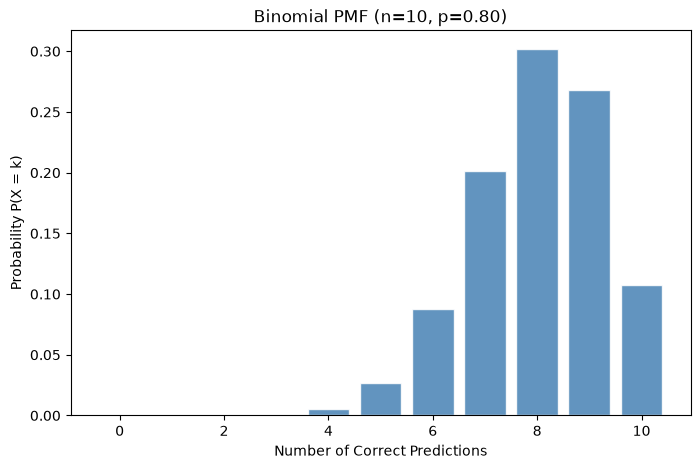

In [19]:
# (a-iii) Plotar a PMF completa (todos os valores de X de 0 a 10)
x_values = np.arange(0, 11)
pmf = binom.pmf(x_values, n, p)

plt.figure(figsize=(8, 5))
plt.bar(x_values, pmf, color='steelblue', edgecolor='white', alpha=0.85)
plt.xlabel('Number of Correct Predictions')
plt.ylabel('Probability P(X = k)')
plt.title('Binomial PMF (n=10, p=0.80)')
plt.show()

## Questão 5 – Código Python e Discursiva: Teorema do Limite Central


### Código 3 Demonstração empírica do Teorema do Limite Central

In [20]:
url = (
    'https://raw.githubusercontent.com/stedy/'
    'Machine-Learning-with-R-datasets/master/insurance.csv'
)

df = pd.read_csv(url)

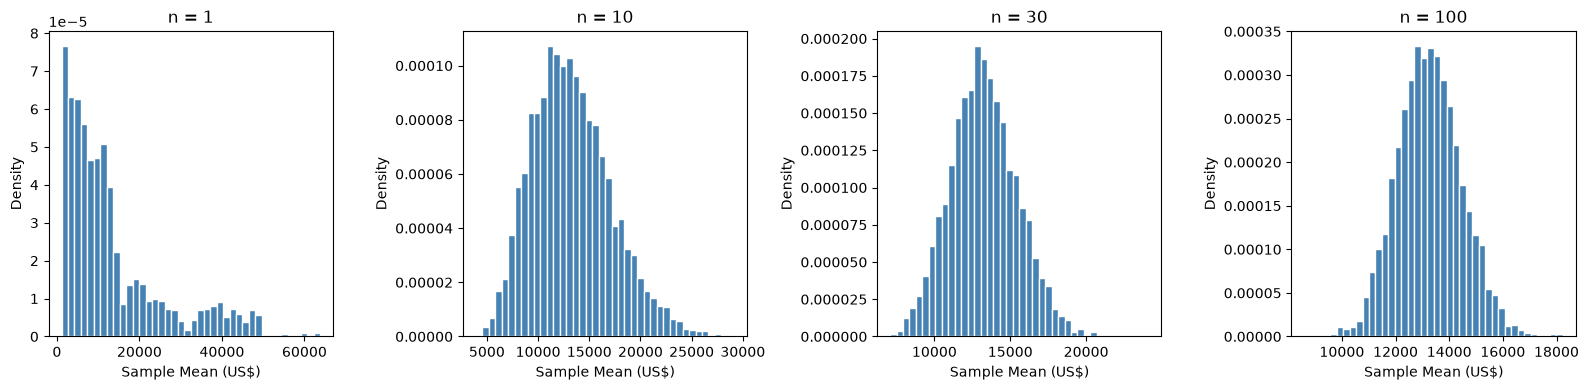

In [29]:
np.random.seed(42)

n_sim = 5000
sample_sizes = [1, 10, 30, 100]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i, n in enumerate(sample_sizes):
# (a-i) Gere n_sim médias amostrais , cada uma calculada sobre n observacoes
    sample_means = [
        df['charges'].sample(n=n, replace=True).mean()
        for _ in range(n_sim)
    ]

    axes[i].hist(sample_means, bins=40, color='steelblue', edgecolor='white', density=True)

    axes[i].set_title(f'n = {n}')
    axes[i].set_xlabel('Sample Mean (US$)')
    axes[i].set_ylabel('Density')

plt.tight_layout()
plt.show()

In [25]:
# (a-ii) Calcule a media teórica e o erro padrão para n = 30
mu_charges = df['charges'].mean()

se_n30 = df['charges'].std() / np.sqrt(30)

print(f'Mean: US$ {mu_charges:.2f}')
print(f'SE(n=30): US$ {se_n30:.2f}')

Mean: US$ 13270.42
SE(n=30): US$ 2210.98
